# Supplementary — insula and frontal operculum

Approved method (2026-10-18): orthogonalize native bandpassed analytic signals
before extracting HGA. Each pair has no shared monopolar contacts. Baseline
undergoes the same transformation. This notebook is separate from main
Figures 1–6 and does not alter their cohort or NMF.

**Current image review:** D0057 uses the matching D57_2 reconstruction;
RAMT9–10 is not confirmed FO there (midpoint: superior temporal sulcus).
D0079 LAI1 has a ~6 mm CT discrepancy. Keep the three affected pair × task
records visible and flagged for review. The prior 15-record counts are
provisional; do not interpret all 15 as confirmed AIC–FO controls.

The result concerns task activity not explained by the selected neighbor's
instantaneous in-phase signal. It does not establish fully independent
neural generators. All eligible analyzed pairs are shown, without selecting
on the result. See `docs/SUPPLEMENTARY_ANALYSIS.md` for the complete method.


In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'.project-root').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
get_ipython().run_line_magic('matplotlib','inline')
set_matplotlib_formats('svg')
from src.main_analysis import TASKS, COHORT_DIR, CONDITION, MODALITY, ROI_COLORS
for path in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(path))
plt.rcParams.update({'svg.fonttype':'none','font.family':'sans-serif',
                     'font.sans-serif':['Arial'],'font.size':7,
                     'axes.linewidth':.75,'xtick.labelsize':7,'ytick.labelsize':7})
cm=1/2.54
TOPIC='operculum'
DATA_DIR=ROOT/'results/supplementary'/TOPIC
IMG_DIR=ROOT/'img/supplementary'/TOPIC
DATA_DIR.mkdir(parents=True,exist_ok=True); IMG_DIR.mkdir(parents=True,exist_ok=True)
from src.main_analysis import TASK_DISPLAY_NAMES
TASK_LABELS=TASK_DISPLAY_NAMES.copy()
def save(fig,name):
    target=IMG_DIR/name
    fig.savefig(target,bbox_inches='tight',dpi=300)
    plt.show();plt.close(fig)
    return target


In [2]:
from src.supplementary.operculum_inputs import audit_inputs
audit=audit_inputs(ROOT,DATA_DIR)
print(json.dumps(audit['summary'],indent=2))


{
  "scope": "Input and anatomy audit only; no new orthogonalization, xcorr, or task-response fit",
  "subject_task_pairs": 118,
  "n_broad_region_candidates": 698,
  "n_explicit_opercular_labels": 25,
  "legacy_opercular_evidence_rows": 82,
  "archived_Destrieux_labels_require_native_identity_and_endpoint_review": true,
  "n_nearest_nonshared_candidates": 518,
  "n_candidates_with_both_native_good_channels": 414,
  "exact_opercular_boundary_requires_review": true,
  "Hammers_IFG_not_equated_to_operculum": true,
  "historical_opercular_notebook": "/hpc/group/coganlab/nanlinshi/insula-aicl-delay/notebooks/opercular.ipynb",
  "historical_method": "Per-trial HGA linear projection residual, without intercept",
  "historical_example_shares_contact": true,
  "analytical_signal_method_pending_review": false,
  "analytical_signal_method_user_approved": "Subband analytic-signal orthogonalization before HGA; no shared contacts",
  "new_orthogonalization_results_generated": false,
  "original_inp

## Approved operation

For each existing 70–200 Hz Gaussian HGA subband, form analytic AIC and FO
signals A and B. The AIC signal orthogonal to FO is
`i * B/abs(B) * imag(A * conj(B)/abs(B))`. Extract its envelope and sum
subbands exactly as in the native IEEG pipeline. Process FO relative to AIC
separately. Apply the same transformation to baseline before normalizing.

Reference: [Hipp et al., 2012](https://doi.org/10.1038/nn.3101).
The old HGA-envelope regression and its shared-contact D0106 example are
not used for the approved control.


In [3]:
proposal={
 'status':'user_approved_2026-10-18',
 'primary_result':'Task-related AIC response after removing FO instantaneous in-phase signal',
 'input':'Matched-trial native bipolar voltage; Repeat + sound; native QC',
 'band':'Existing 70–200 Hz analytic subbands; orthogonalize before envelopes',
 'directions':['AIC relative to FO','FO relative to AIC'],
 'baseline':'Same orthogonalization and native HGA extraction applied to baseline',
 'sampling':'Native Destrieux FO; frozen sampled Hammers AIC; no shared contacts',
 'pairing':'Nearest eligible FO within subject/task/hemisphere, before inspecting responses',
 'statistical_unit':'Per-channel/phase native tests; no pooled independent-pair group test',
 'analysis_executed':bool(list((DATA_DIR/'pairs').glob('*/completed.json')))}
(DATA_DIR/'orthogonalization_proposal.json').write_text(json.dumps(proposal,indent=2)+'\n')
display(pd.DataFrame(proposal.items(),columns=['Item','Approved definition']))


,Item,Approved definition
0,status,user_approved_2026-10-18
1,primary_result,Task-related AIC response after removing FO in...
2,input,Matched-trial native bipolar voltage; Repeat +...
3,band,Existing 70–200 Hz analytic subbands; orthogon...
4,directions,"[AIC relative to FO, FO relative to AIC]"
5,baseline,Same orthogonalization and native HGA extracti...
6,sampling,Native Destrieux FO; frozen sampled Hammers AI...
7,pairing,Nearest eligible FO within subject/task/hemisp...
8,statistical_unit,Per-channel/phase native tests; no pooled inde...
9,analysis_executed,True


## Native anatomy and signal availability

FO midpoint: native Destrieux `G_front_inf-Opercular`; endpoints: FO gray
matter or white matter. Names/positions must match native reconstruction.
Known CSF and Hammers-insula conflicts remain excluded or unresolved.
Current task-specific sampled AIC sites provide the insular side. A broad
Hammers IFG label alone is insufficient to call a site FO.

The table includes unavailable inputs. Only complete raw epochs with native
restoration validation (when staged) enter processing. Distances are in
native millimeters. Repeated FO sites are retained explicitly.
The existing pair-list labels precede the matching-image review. The
current contact labels and review flags below supersede those historical
anatomy claims; no signal result or main cohort is silently changed.


In [4]:
native_summary=json.loads((DATA_DIR/'native_pair_audit.json').read_text())
pair_list=pd.read_csv(DATA_DIR/'native_verified_pairs.csv')
print(json.dumps(native_summary,indent=2))
display(pair_list[['task','subject','insula_site','operculum_site','native_distance_mm',
                  'operculum_endpoint_1','operculum_endpoint_2','ready_for_analysis']])


{
  "native_fo_sites": 95,
  "endpoint_eligible_fo_sites": 51,
  "n_pairs": 22,
  "n_pairs_with_raw_epochs": 15,
  "n_pairs_ready_for_analysis": 15,
  "selection_uses_hga_response": false,
  "rules": "Frozen sampled AIC; native Destrieux FO midpoint; FO/WM endpoints; original QC; no shared contacts; nearest eligible FO within subject/task/hemisphere",
  "main_cohort_changed": false
}


,task,subject,insula_site,operculum_site,native_distance_mm,operculum_endpoint_1,operculum_endpoint_2,ready_for_analysis
0,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,40.869841,Left-Cerebral-White-Matter,ctx_lh_G_front_inf-Opercular,True
1,LexicalDelay,D0079,D0079_LAI2-3,D0079_LFMI7-8,38.097053,Left-Cerebral-White-Matter,ctx_lh_G_front_inf-Opercular,True
2,LexicalDelay,D0079,D0079_LAI3-4,D0079_LFMI7-8,35.434431,Left-Cerebral-White-Matter,ctx_lh_G_front_inf-Opercular,True
3,LexicalDelay,D0079,D0079_LAI7-8,D0079_LFMI7-8,26.943797,Left-Cerebral-White-Matter,ctx_lh_G_front_inf-Opercular,True
4,LexicalDelay,D0094,D0094_LFAI2-3,D0094_LFAI8-9,20.761577,Left-Cerebral-White-Matter,Left-Cerebral-White-Matter,True
5,LexicalDelay,D0094,D0094_LIA3-4,D0094_LFAI8-9,27.470065,Left-Cerebral-White-Matter,Left-Cerebral-White-Matter,True
6,LexicalDelay,D0096,D0096_LFAI1-2,D0096_LFAI3-4,7.039572,ctx_lh_G_front_inf-Opercular,ctx_lh_G_front_inf-Opercular,False
7,LexicalDelay,D0096,D0096_LIA3-4,D0096_LFAI3-4,17.072195,ctx_lh_G_front_inf-Opercular,ctx_lh_G_front_inf-Opercular,False
8,PhonemeSequence,D0057,D0057_RAI3-4,D0057_RAMT9-10,32.664068,ctx_rh_G_front_inf-Opercular,Right-Cerebral-White-Matter,True
9,PhonemeSequence,D0094,D0094_LFAI2-3,D0094_LFAI8-9,20.761577,Left-Cerebral-White-Matter,Left-Cerebral-White-Matter,False


## Executed results and implementation checks

Native HGA must match the untouched branch and saved native power.
A purely in-phase mixture must be removed and a quadrature component kept.
Tests: native `time_perm_cluster`, 5000 permutations, one-tailed, cluster
forming p=0.1, final p<0.05, channel adjacency ignored, separate per phase.
Summary windows: Stimulus 0–0.6 s, Delay 0–1 s, Response −0.5–0.5 s.
No test assumes that repeated FO sites or AIC sites across tasks are
independent. A branch's z score uses its own transformed baseline; z-score
ratios are not physical amplitude retention fractions.


In [5]:
from datetime import datetime,timezone
from src.main_analysis import RESPONSE_WINDOWS
receipts=[];tables=[];checks=[]
allowed={f'{r.task}__{r.insula_site}__{r.operculum_site}' for r in pair_list.itertuples() if r.ready_for_analysis}
for path in sorted((DATA_DIR/'pairs').glob('*/completed.json')):
    receipt=json.loads(path.read_text())
    if receipt['pair_id'] not in allowed: continue
    assert receipt['n_perm']==5000 and receipt['nonshared_contacts']
    assert receipt['verification']['native_filterbank_match']
    # A receipt from an earlier code version must be rerun before display.
    assert receipt.get('code_sha256'), 'Missing current processing-code provenance'
    for filename,digest in receipt['code_sha256'].items():
        assert hashlib.sha256(Path(filename).read_bytes()).hexdigest()==digest
    table=pd.read_csv(path.parent/'response_summary.csv')
    for phase,group in table.groupby('phase'):
        assert np.allclose(group.window_start,RESPONSE_WINDOWS[phase.lower()][0])
        assert np.allclose(group.window_end,RESPONSE_WINDOWS[phase.lower()][1])
    assert table.saved_native_power_match.eq(True).all()
    tables.append(table);receipts.append(receipt)
    checks.append(dict(pair_id=receipt['pair_id'],**receipt['verification']))
assert receipts, 'No completed native orthogonalization result yet'
assert {r['pair_id'] for r in receipts}==allowed, 'Some ready pairs have not completed analysis'
results=pd.concat(tables,ignore_index=True)
results.to_csv(DATA_DIR/'response_summary.csv',index=False)
pd.DataFrame(checks).to_json(DATA_DIR/'signal_verification_summary.json',orient='records',indent=2)
analyzed_pairs=pair_list.loc[[f'{r.task}__{r.insula_site}__{r.operculum_site}' in {v['pair_id'] for v in receipts} for r in pair_list.itertuples()]].copy()
coordinate_source=ROOT/'results/audit/sound_only_cohort_2026-10-17/coordinate_variants.csv'
coordinates=pd.read_csv(coordinate_source,usecols=['task','channel','description','modality','x_native','y_native','z_native'])
coordinates=coordinates.loc[coordinates.description.eq('Repeat')&coordinates.modality.eq('sound')].drop(columns=['description','modality']).drop_duplicates()
for side,sitecolumn in [('aic','insula_site'),('fo','operculum_site')]:
    points=coordinates.rename(columns={'channel':sitecolumn,**{axis+'_native':side+'_'+axis+'_native' for axis in ['x','y','z']}})
    points=points.merge(analyzed_pairs[['task',sitecolumn]].drop_duplicates(),on=['task',sitecolumn],how='inner',validate='many_to_one')
    analyzed_pairs=analyzed_pairs.merge(points,on=['task',sitecolumn],how='left',validate='many_to_one')
measured=np.linalg.norm(analyzed_pairs[['aic_x_native','aic_y_native','aic_z_native']].to_numpy()-analyzed_pairs[['fo_x_native','fo_y_native','fo_z_native']].to_numpy(),axis=1)
assert np.allclose(measured,analyzed_pairs.native_distance_mm)
analyzed_pairs.to_csv(DATA_DIR/'paired_coordinates.csv',index=False)
display(results[['task','subject','insula_site','operculum_site','phase','condition',
                 'n_trials','mean_response_z','baseline_subtracted_response_uv','significant_in_window']])


,task,subject,insula_site,operculum_site,phase,condition,n_trials,mean_response_z,baseline_subtracted_response_uv,significant_in_window
0,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,Stimulus,AIC_before,168,0.073210,0.050655,False
1,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,Stimulus,AIC_orthogonal,168,0.054021,0.032251,False
2,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,Stimulus,FO_before,168,-0.159006,-0.481592,False
3,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,Stimulus,FO_orthogonal,168,-0.130167,-0.286883,False
4,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,Delay,AIC_before,168,0.084251,0.058294,False
...,...,...,...,...,...,...,...,...,...,...
175,SentenceRep,D0102,D0102_RFAI1-2,D0102_RFAI3-4,Delay,FO_orthogonal,60,-0.300065,-0.291426,False
176,SentenceRep,D0102,D0102_RFAI1-2,D0102_RFAI3-4,Response,AIC_before,58,0.189544,0.474710,True
177,SentenceRep,D0102,D0102_RFAI1-2,D0102_RFAI3-4,Response,AIC_orthogonal,58,0.144253,0.291494,True
178,SentenceRep,D0102,D0102_RFAI1-2,D0102_RFAI3-4,Response,FO_before,58,0.145198,0.172474,True


## Every analyzed pair: before/after task responses

Solid: before orthogonalization. Dashed: after removing the partner's
instantaneous in-phase signal. Lines are within-site trial means; no group
SEM is constructed from dependent pairs. Lower tick rows mark native
time-cluster significance before (gray) and after (ROI color). The two rows
of each figure share their phase-wise y scale. All analyzed pairs are shown.

Immediately after each waveform, show that same pair on wide-context native
MRI planes and its individual native 3D brain. CT is not displayed. Circles mark the four real
contacts; diamonds mark the two virtual bipolar midpoints. Two perpendicular
oblique planes contain each bipole's contact axis and show a 180 mm field
with labeled insula and frontal operculum boundaries. Following Figure 1,
3D views show every reconstructed contact as a physical cylindrical contact on the complete shank, following the user-confirmed Figure 1 SEEG illustration.
Native insula contacts are purple, native frontal operculum contacts blue,
and other contacts gray; selected pairs retain colored rings and diamonds.
MRI uses upright native sagittal/coronal planes. Contacts within ±4 mm are projected onto the displayed slice, following Figure 1; this is not a 1-mm tissue slab. Marker area is reduced to 6 pt² for endpoints and 9 pt² for bipolar midpoints.
Coordinates are not
snapped to the cortex. Native tissue/region labels are printed, including
white-matter endpoints, rather than relabeling every contact as gray matter.


For point-by-point review, open the [offline MRI/contact inspector](/cwork/ns458/insula-paper/results/supplementary/operculum/viewer/operculum-inspector.html). All real contacts on the selected shanks remain selectable, including gray and Unknown contacts. Atlas overlay is optional; manual review exports do not update the analysis cohort.


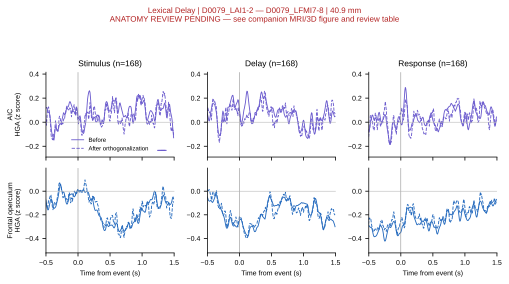

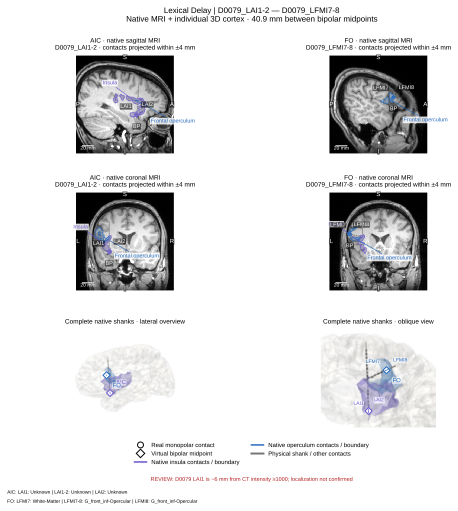

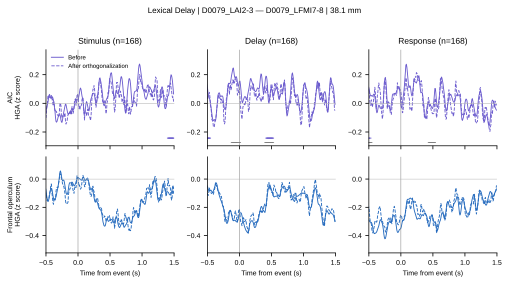

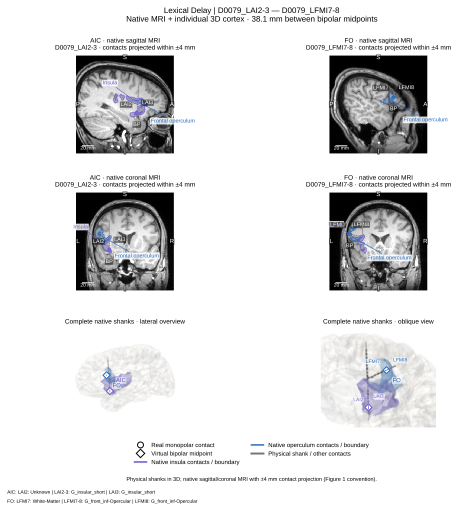

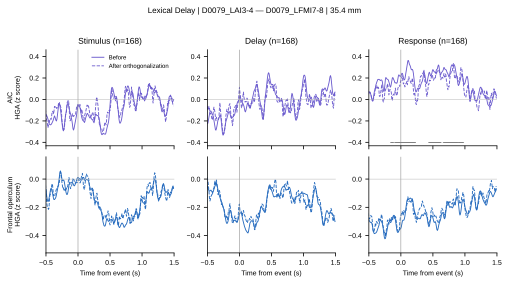

...

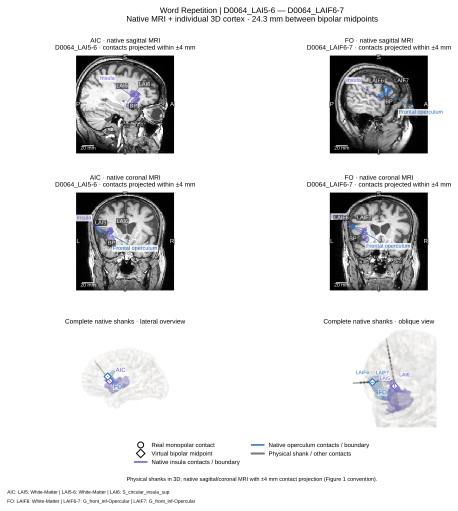

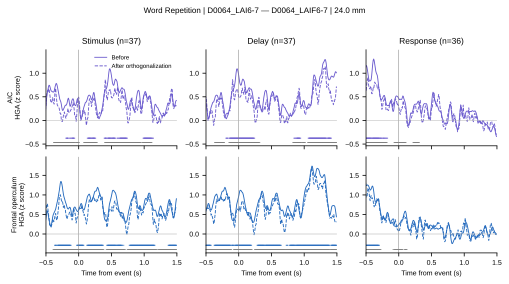

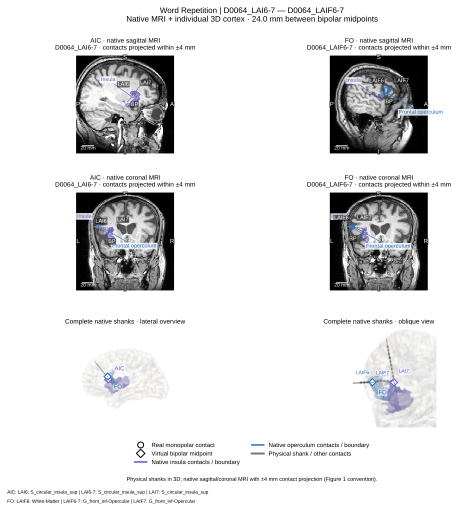

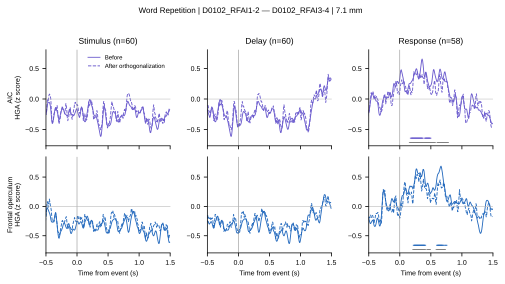

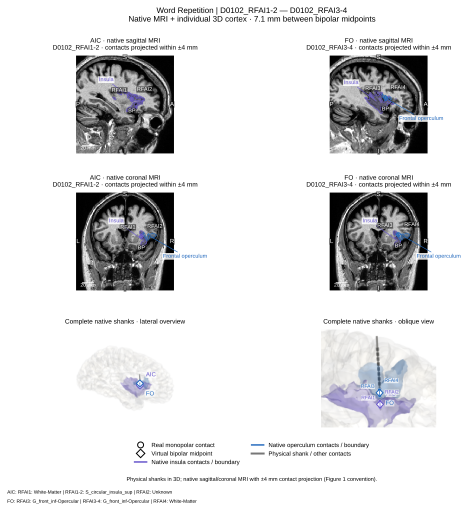

,pair_id,task,subject,reconstruction,requires_review,review_reason,current_FO_candidate_midpoint
0,LexicalDelay__D0079_LAI1-2__D0079_LFMI7-8,LexicalDelay,D0079,D79,True,D0079 LAI1 is ~6 mm from CT intensity ≥1000; l...,ctx_lh_G_front_inf-Opercular
1,LexicalDelay__D0079_LAI2-3__D0079_LFMI7-8,LexicalDelay,D0079,D79,False,,ctx_lh_G_front_inf-Opercular
2,LexicalDelay__D0079_LAI3-4__D0079_LFMI7-8,LexicalDelay,D0079,D79,False,,ctx_lh_G_front_inf-Opercular
3,LexicalDelay__D0079_LAI7-8__D0079_LFMI7-8,LexicalDelay,D0079,D79,False,,ctx_lh_G_front_inf-Opercular
4,LexicalDelay__D0094_LFAI2-3__D0094_LFAI8-9,LexicalDelay,D0094,D94,False,,ctx_lh_G_front_inf-Opercular
5,LexicalDelay__D0094_LIA3-4__D0094_LFAI8-9,LexicalDelay,D0094,D94,False,,ctx_lh_G_front_inf-Opercular
6,PhonemeSequence__D0057_RAI3-4__D0057_RAMT9-10,PhonemeSequence,D0057,D57_2,True,FO candidate midpoint is S_temporal_sup in mat...,ctx_rh_S_temporal_sup
7,SentenceRep__D0032_LAI1-2__D0032_LAI6-7,SentenceRep,D0032,D32,False,,ctx_lh_G_front_inf-Opercular
8,SentenceRep__D0032_LAI2-3__D0032_LAI6-7,SentenceRep,D0032,D32,False,,ctx_lh_G_front_inf-Opercular
9,SentenceRep__D0057_RAI3-4__D0057_RAMT9-10,SentenceRep,D0057,D57_2,True,FO candidate midpoint is S_temporal_sup in mat...,ctx_rh_S_temporal_sup


In [6]:
from src.supplementary.operculum_anatomy import make_pair_figure,load_subject,pair_points,localization_review_notes
trace_exports=[];anatomy_exports=[];anatomy_tables=[];anatomy_review=[]
for receipt in receipts:
    pair_id=receipt['pair_id'];directory=DATA_DIR/'pairs'/pair_id
    info=receipt['pair'];phase_data={p:np.load(directory/f'{p}.npz') for p in ['Stimulus','Delay','Response']}
    native_subject=load_subject(info['subject'],info['hemisphere'])
    native_points=pair_points(info,native_subject)
    review_notes=localization_review_notes(info,native_points)
    anatomy_review.append(dict(pair_id=pair_id,task=info['task'],subject=info['subject'],
        reconstruction=native_subject['recon'],requires_review=bool(review_notes),
        review_reason='; '.join(review_notes),
        current_FO_candidate_midpoint=native_points.loc[native_points.region.eq('FO')&native_points.role.eq('midpoint'),'native_aparc'].iloc[0]))
    fo_display='FO candidate (review)' if any(n.startswith('FO candidate') for n in review_notes) else 'Frontal operculum'
    fig,axes=plt.subplots(2,3,figsize=(18*cm,10*cm),sharex=True)
    for row,(name,indices,color) in enumerate([
        ('AIC',[0,1],ROI_COLORS['Insula']),(fo_display,[2,3],ROI_COLORS['IFG'])]):
        waves=[np.nanmean(data['zscore'][:,indices,:],axis=0) for data in phase_data.values()]
        values=np.concatenate(waves,axis=-1)
        low=min(0.,float(np.nanmin(values)));high=max(0.,float(np.nanmax(values)))
        pad=max(.1,(high-low)*.12)
        for col,(phase,data) in enumerate(phase_data.items()):
            ax=axes[row,col];times=data['times'];wave=waves[col]
            for branch,(idx,style) in enumerate(zip(indices,['-','--'])):
                ax.plot(times,wave[branch],color=color,lw=.9,ls=style,
                        label='Before' if branch==0 else 'After orthogonalization')
                sig=np.asarray(data['mask'][idx],dtype=bool) & (data['pvals'][idx]<.05)
                ax.scatter(times[sig],np.full(sig.sum(),.035+branch*.045),marker='_',s=5,
                           color='0.5' if branch==0 else color,transform=ax.get_xaxis_transform(),linewidths=.7)
            ax.axvline(0,color='0.5',lw=.5);ax.axhline(0,color='0.7',lw=.5)
            ax.set_xlim(-.5,1.5);ax.set_ylim(low-pad,high+pad)
            ax.spines[['top','right']].set_visible(False)
            if row==0:ax.set_title(f'{phase} (n={len(data["zscore"])})')
            if col==0:ax.set_ylabel(name+'\nHGA (z score)')
            if row==1:ax.set_xlabel('Time from event (s)')
    axes[0,0].legend(frameon=False,fontsize=6,loc='best')
    title=f'{TASK_LABELS[info["task"]]} | {info["insula_site"]} — {info["operculum_site"]} | {info["native_distance_mm"]:.1f} mm'
    if review_notes:title+='\nANATOMY REVIEW PENDING — see companion MRI/3D figure and review table'
    fig.suptitle(title,fontsize=8,color='#B22222' if review_notes else 'black')
    fig.tight_layout(rect=(0,0,1,.90 if review_notes else .95))
    trace_exports.append(str(save(fig,f'{pair_id}__before_after.svg')))
    anatomy_fig,anatomy_points=make_pair_figure(info)
    anatomy_exports.append(str(save(anatomy_fig,f'{pair_id}__anatomy.svg')))
    anatomy_tables.append(anatomy_points.assign(pair_id=pair_id))
all_anatomy_points=pd.concat(anatomy_tables,ignore_index=True)
assert len(anatomy_exports)==len(receipts)
assert len(all_anatomy_points)==6*len(receipts)
all_anatomy_points.to_csv(DATA_DIR/'anatomy/all_pair_points.csv',index=False)
full_shanks=pd.concat([pd.read_csv(DATA_DIR/'anatomy'/f"{r['pair_id']}__shanks.csv",keep_default_na=False) for r in receipts],ignore_index=True)
assert full_shanks.groupby('pair_id').selected_pair.apply(lambda x:x.ne('').sum()).eq(4).all()
full_shanks.to_csv(DATA_DIR/'anatomy/complete_shank_contacts.csv',index=False)
anatomy_review=pd.DataFrame(anatomy_review)
anatomy_review.to_csv(DATA_DIR/'anatomy/current_anatomy_review.csv',index=False)
display(anatomy_review)


## All-pair descriptive comparison

Each numbered point is one AIC site × task pairing, indexed by the companion
table. Repeated sites and shared FO partners are not independent subjects.
This provisional display retains the flagged anatomy-review records;
their identities are listed in `anatomy/current_anatomy_review.csv`.
Top: normalized responses. Bottom: task minus matching baseline in physical
envelope units. The diagonal indicates equal before/after response. Negative
or non-significant responses are retained. This is not a group hypothesis test.


,index,pair_id,task,subject,insula_site,operculum_site,distance_mm
0,1,LexicalDelay__D0079_LAI1-2__D0079_LFMI7-8,LexicalDelay,D0079,D0079_LAI1-2,D0079_LFMI7-8,40.869841
1,2,LexicalDelay__D0079_LAI2-3__D0079_LFMI7-8,LexicalDelay,D0079,D0079_LAI2-3,D0079_LFMI7-8,38.097053
2,3,LexicalDelay__D0079_LAI3-4__D0079_LFMI7-8,LexicalDelay,D0079,D0079_LAI3-4,D0079_LFMI7-8,35.434431
3,4,LexicalDelay__D0079_LAI7-8__D0079_LFMI7-8,LexicalDelay,D0079,D0079_LAI7-8,D0079_LFMI7-8,26.943797
4,5,LexicalDelay__D0094_LFAI2-3__D0094_LFAI8-9,LexicalDelay,D0094,D0094_LFAI2-3,D0094_LFAI8-9,20.761577
5,6,LexicalDelay__D0094_LIA3-4__D0094_LFAI8-9,LexicalDelay,D0094,D0094_LIA3-4,D0094_LFAI8-9,27.470065
6,7,PhonemeSequence__D0057_RAI3-4__D0057_RAMT9-10,PhonemeSequence,D0057,D0057_RAI3-4,D0057_RAMT9-10,32.664068
7,8,SentenceRep__D0032_LAI1-2__D0032_LAI6-7,SentenceRep,D0032,D0032_LAI1-2,D0032_LAI6-7,16.530275
8,9,SentenceRep__D0032_LAI2-3__D0032_LAI6-7,SentenceRep,D0032,D0032_LAI2-3,D0032_LAI6-7,13.536986
9,10,SentenceRep__D0057_RAI3-4__D0057_RAMT9-10,SentenceRep,D0057,D0057_RAI3-4,D0057_RAMT9-10,32.664068


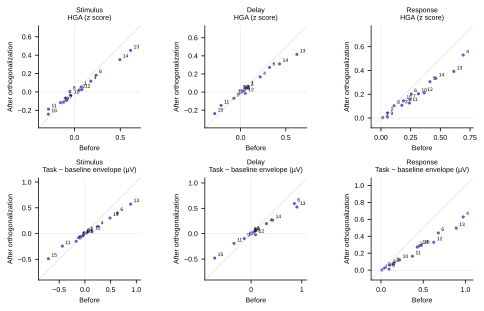

PosixPath('/cwork/ns458/insula-paper/img/supplementary/operculum/supp_operculum_all_pair_responses.svg')

In [7]:
pair_order=[r['pair_id'] for r in receipts]
pair_index=pd.DataFrame([dict(index=i+1,pair_id=r['pair_id'],task=r['pair']['task'],
    subject=r['pair']['subject'],insula_site=r['pair']['insula_site'],
    operculum_site=r['pair']['operculum_site'],distance_mm=r['pair']['native_distance_mm'])
    for i,r in enumerate(receipts)])
pair_index.to_csv(DATA_DIR/'pair_index.csv',index=False)
display(pair_index)
fig,axes=plt.subplots(2,3,figsize=(18*cm,11*cm))
for col,phase in enumerate(['Stimulus','Delay','Response']):
    for row,(metric,label) in enumerate([('mean_response_z','HGA (z score)'),
            ('baseline_subtracted_response_uv','Task − baseline envelope (µV)')]):
        frame=results.loc[results.phase.eq(phase)&results.condition.str.startswith('AIC_')]
        pivot=frame.pivot(index='pair_id',columns='condition',values=metric).reindex(pair_order)
        x=pivot['AIC_before'].to_numpy();y=pivot['AIC_orthogonal'].to_numpy();ax=axes[row,col]
        lo=min(0.,float(np.min([x,y])));hi=max(0.,float(np.max([x,y])))
        pad=max(1e-3,(hi-lo)*.12);bounds=(lo-pad,hi+pad)
        ax.plot(bounds,bounds,color='0.65',lw=.6,ls=':')
        ax.scatter(x,y,s=10,color=ROI_COLORS['Insula'],edgecolors='none')
        for i,(xx,yy) in enumerate(zip(x,y)):ax.annotate(str(i+1),(xx,yy),xytext=(3,2),textcoords='offset points',fontsize=5)
        ax.set_xlim(bounds);ax.set_ylim(bounds);ax.set_aspect('equal',adjustable='box')
        ax.axvline(0,color='0.85',lw=.4);ax.axhline(0,color='0.85',lw=.4)
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlabel('Before');ax.set_ylabel('After orthogonalization')
        ax.set_title(f'{phase}\n{label}',fontsize=7)
fig.tight_layout();save(fig,'supp_operculum_all_pair_responses.svg')


In [8]:
after=results.loc[results.condition.eq('AIC_orthogonal')]
before=results.loc[results.condition.eq('AIC_before')]
paired=before[['pair_id','phase','significant_in_window']].merge(
    after[['pair_id','phase','significant_in_window']],on=['pair_id','phase'],suffixes=('_before','_after'),validate='one_to_one')
paired['significant_both']=paired.significant_in_window_before & paired.significant_in_window_after
counts=paired.groupby('phase').agg(n_pair_task_records=('pair_id','size'),
    significant_before=('significant_in_window_before','sum'),significant_after=('significant_in_window_after','sum'),
    significant_before_and_after=('significant_both','sum'))
counts.to_csv(DATA_DIR/'descriptive_response_counts.csv')
display(counts)
manifest=dict(method_status='user_approved_2026-10-18',method='Analytic subband quadrature before HGA',
    n_analyzed_pair_task_records=len(receipts),n_unique_aic_sites=analyzed_pairs.insula_site.nunique(),
    n_subjects=analyzed_pairs.subject.nunique(),tasks=sorted(analyzed_pairs.task.unique()),
    pending_pair_task_records=int(len(pair_list)-len(receipts)),
    main_cohort_changed=False,group_inference_performed=False,all_analyzed_pairs_shown=True,
    reference='https://doi.org/10.1038/nn.3101',
    figures=trace_exports+anatomy_exports+[str(IMG_DIR/'supp_operculum_all_pair_responses.svg')],
    paired_anatomy_figures=len(anatomy_exports),
    anatomy_review_pending_records=int(anatomy_review.requires_review.sum()),
    anatomy_review_table=str(DATA_DIR/'anatomy/current_anatomy_review.csv'),
    response_counts_status='Provisional over all 15 previously computed records, including anatomy-review flags; not 15 confirmed AIC-FO controls',
    anatomy_coordinates='Original native tkRAS, four real contacts and two exact bipolar midpoints per pair; no cortical snapping',
    anatomy_point_table=str(DATA_DIR/'anatomy/all_pair_points.csv'),
    full_shank_contact_table=str(DATA_DIR/'anatomy/complete_shank_contacts.csv'),
    full_shanks_in_3D=True,physical_cylindrical_contacts=True,
    MRI_projection_tolerance_mm=4.,MRI_projection_is_not_a_slab=True,
    MRI_planes=['native sagittal','native coronal'],
    anatomy_render_code_sha256=hashlib.sha256((ROOT/'src/supplementary/operculum_anatomy.py').read_bytes()).hexdigest(),
    receipts=[str(DATA_DIR/'pairs'/r['pair_id']/'completed.json') for r in receipts],
    pair_list_sha256=hashlib.sha256((DATA_DIR/'native_verified_pairs.csv').read_bytes()).hexdigest(),
    limitation='Retained task responses do not prove independent neural generators or exclude every shared source.',
    completed_utc=datetime.now(timezone.utc).isoformat())
(DATA_DIR/'figure_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print(json.dumps(manifest,indent=2))


,n_pair_task_records,significant_before,significant_after,significant_before_and_after
phase,,,,
Delay,15,5,5,5
Response,15,13,10,10
Stimulus,15,4,4,4


{
  "method_status": "user_approved_2026-10-18",
  "method": "Analytic subband quadrature before HGA",
  "n_analyzed_pair_task_records": 15,
  "n_unique_aic_sites": 14,
  "n_subjects": 6,
  "tasks": [
    "LexicalDelay",
    "PhonemeSequence",
    "SentenceRep"
  ],
  "pending_pair_task_records": 7,
  "main_cohort_changed": false,
  "group_inference_performed": false,
  "all_analyzed_pairs_shown": true,
  "reference": "https://doi.org/10.1038/nn.3101",
  "figures": [
    "/cwork/ns458/insula-paper/img/supplementary/operculum/LexicalDelay__D0079_LAI1-2__D0079_LFMI7-8__before_after.svg",
    "/cwork/ns458/insula-paper/img/supplementary/operculum/LexicalDelay__D0079_LAI2-3__D0079_LFMI7-8__before_after.svg",
    "/cwork/ns458/insula-paper/img/supplementary/operculum/LexicalDelay__D0079_LAI3-4__D0079_LFMI7-8__before_after.svg",
    "/cwork/ns458/insula-paper/img/supplementary/operculum/LexicalDelay__D0079_LAI7-8__D0079_LFMI7-8__before_after.svg",
    "/cwork/ns458/insula-paper/img/supplemen